Saving movie_dataset_selected_features.csv to movie_dataset_selected_features (1).csv
Dataset loaded successfully!
Dataset shape: (4159, 11)

Original selected features: 10
Principal components: 8
Variance retained: 95.76 %


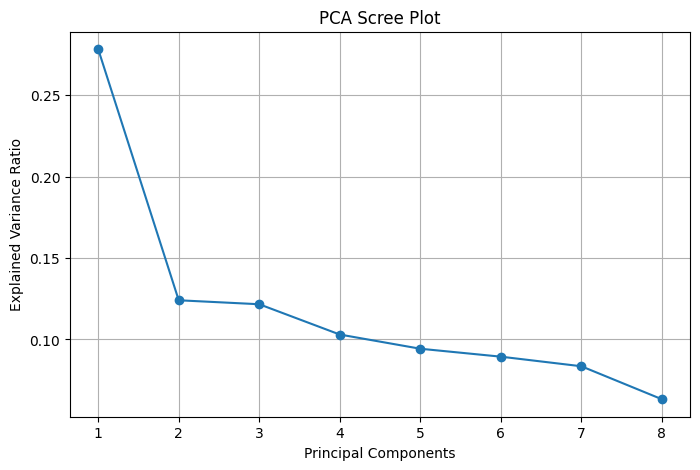

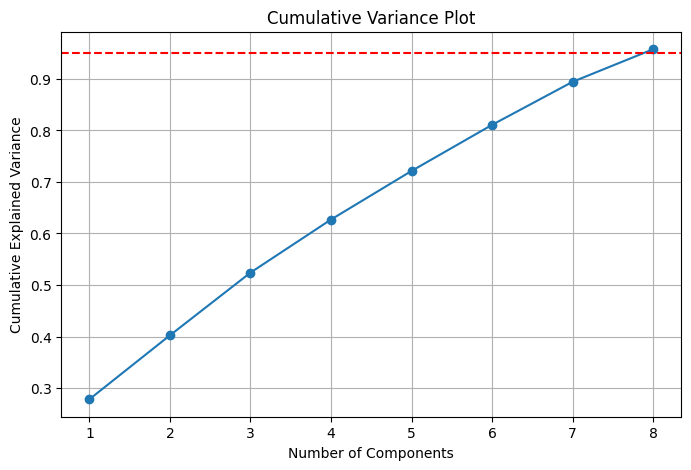

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from google.colab import files

# Step 1: Load the feature-selected dataset
uploaded = files.upload()

filename = list(uploaded.keys())[0]
selected_dataset = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", selected_dataset.shape)

# Step 2: Remove target variable
X = selected_dataset.drop(columns=['gross'], errors='ignore')

# Step 3: Select numerical features
X = X.select_dtypes(include=np.number)

# Step 4: Handle missing values
X = X.fillna(X.median())

# Step 5: Standardize the selected features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 6: Apply PCA (95% variance)
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)

# Step 7: Create PCA dataset
pca_dataset = pd.DataFrame(
    X_pca,
    columns=[f'PC{i+1}' for i in range(X_pca.shape[1])]
)

# Step 8: Display results
print("\nOriginal selected features:", X.shape[1])
print("Principal components:", X_pca.shape[1])

print("Variance retained:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

# Step 9: Scree Plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
         pca.explained_variance_ratio_, marker='o')
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Scree Plot")
plt.grid()
plt.show()

# Step 10: Cumulative Variance Plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
         np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.axhline(y=0.95, color='red', linestyle='--')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Variance Plot")
plt.grid()
plt.show()

# Step 11: Download PCA dataset
pca_dataset.to_csv("selected_dataset_pca.csv", index=False)

files.download("selected_dataset_pca.csv")